# 🏎️ Predicción del Resultado en Carreras de F1 con XGBoost

**TFM — Master en Inteligencia Artificial · UTAMED**  
**Autor:** Víctor Ferrer  
**Dataset:** `f1_dataset_v2.csv` — 25.121 registros, carreras 1950–2024  

---

## Objetivo

Predecir la **posición final** de un piloto en una carrera de Fórmula 1 (`positionOrder`) a partir de información disponible **antes o durante** la carrera, sin incurrir en *data leakage*.

## Features del modelo

| Feature | Descripción | Tipo |
|---|---|---|
| `grid` | Posición de salida (clasificación) | Pre-carrera |
| `driver_pos_before` | Posición del piloto en el campeonato | Pre-carrera |
| `driver_wins_before` | Victorias del piloto en la temporada | Pre-carrera |
| `constructor_pos_before` | Posición del constructor | Pre-carrera |
| `driver_experience` | Número de carreras previas disputadas | Pre-carrera |
| `driver_age` | Edad del piloto el día de la carrera | Pre-carrera |
| `avg_finish_last3` | Media de posición en las últimas 3 carreras | Pre-carrera |
| `circuit_alt` | Altitud del circuito (metros) | Contextual |
| `year` | Año de la carrera | Contextual |
| `season_progress` | Progreso de la temporada (round / total) | Contextual |

## Estructura del Notebook

1. ⚙️ Configuración inicial y carga de datos
2. 🔍 Optimización de hiperparámetros (RandomizedSearchCV)
3. 🚀 Entrenamiento final con Early Stopping
4. 📊 Análisis de resultados y métricas
5. 🧠 Explicabilidad global y local con SHAP
6. 📝 Conclusiones y justificación para la memoria del TFM

---
# 1. ⚙️ Configuración Inicial y Carga de Datos

### 1.1 Instalación de dependencias

Instalamos las librerías que no vienen preinstaladas en Google Colab por defecto.

In [1]:
# Instalar librerías no incluidas por defecto en Colab
!pip install xgboost --quiet
!pip install shap --quiet

### 1.2 Importación de librerías

In [2]:
# === Librerías estándar ===
import warnings
import os

warnings.filterwarnings("ignore")

# === Manipulación de datos ===
import numpy as np
import pandas as pd

# === Visualización ===
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

# === Machine Learning — preprocesado y evaluación ===
from sklearn.model_selection import (
    train_test_split,
    RandomizedSearchCV,
    KFold,
    learning_curve,
)
from sklearn.metrics import (
    r2_score,
    mean_squared_error,
    mean_absolute_error,
)
from sklearn.inspection import permutation_importance

# === XGBoost ===
from xgboost import XGBRegressor
import xgboost as xgb

# === Explicabilidad ===
import shap

# === Configuración visual global ===
sns.set_theme(style="whitegrid", palette="muted", font_scale=1.1)
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print(f"XGBoost version : {xgb.__version__}")
print(f"SHAP version    : {shap.__version__}")
print("Librerías cargadas correctamente.")

XGBoost version : 3.2.0
SHAP version    : 0.51.0
Librerías cargadas correctamente.


### 1.3 Carga del dataset

Ejecuta la celda siguiente y selecciona el archivo `f1_dataset_v2.csv` desde tu equipo cuando aparezca el botón de subida.  
El archivo quedará disponible en `/content/f1_dataset_v2.csv` durante toda la sesión de Colab.

In [3]:
from google.colab import files

# Abre el explorador de archivos para seleccionar f1_dataset_v2.csv
uploaded = files.upload()

CSV_PATH = "/content/f1_dataset_v2.csv"
print(f"Archivo cargado: {CSV_PATH}")

Saving f1_dataset_v2.csv to f1_dataset_v2 (1).csv
Archivo cargado: /content/f1_dataset_v2.csv


### 1.4 Exploración inicial del dataset

In [4]:
# Carga
df = pd.read_csv(CSV_PATH)

print(f"Dimensiones : {df.shape[0]:,} filas × {df.shape[1]} columnas")
print(f"Valores NaN : {df.isna().sum().sum()}")
print()
display(df.head())
display(df.describe().round(3))

Dimensiones : 25,121 filas × 11 columnas
Valores NaN : 0



,grid,driver_pos_before,driver_wins_before,constructor_pos_before,driver_experience,driver_age,avg_finish_last3,circuit_alt,year,season_progress,positionOrder
0,1,20.0,0.0,10.0,17,23.186858,9.000000,10,2008,0.055556,1
1,5,20.0,0.0,10.0,133,30.850103,9.000000,10,2008,0.055556,2
2,7,20.0,0.0,10.0,35,22.718686,12.666667,10,2008,0.055556,3
3,11,20.0,0.0,10.0,105,26.631075,8.666667,10,2008,0.055556,4
4,3,20.0,0.0,10.0,17,26.406571,9.333333,10,2008,0.055556,5


,grid,driver_pos_before,driver_wins_before,constructor_pos_before,driver_experience,driver_age,avg_finish_last3,circuit_alt,year,season_progress,positionOrder
count,25121.000,25121.000,25121.000,25121.000,25121.000,25121.000,25121.000,25121.000,25121.000,25121.000,25121.000
mean,11.861,13.806,0.330,6.627,68.241,29.990,12.125,276.507,1991.969,0.535,11.859
std,6.830,8.701,1.104,3.633,68.745,5.282,5.291,406.993,20.161,0.288,6.825
min,1.000,1.000,0.000,1.000,0.000,17.454,1.000,-7.000,1950.000,0.042,1.000
25%,6.000,7.000,0.000,3.000,16.000,26.108,8.667,18.000,1977.000,0.286,6.000
50%,12.000,14.000,0.000,7.000,46.000,29.446,12.333,153.000,1993.000,0.533,12.000
75%,17.000,20.000,0.000,10.000,100.000,33.320,15.667,401.000,2010.000,0.786,17.000
max,34.000,102.000,18.000,20.000,403.000,55.797,36.333,2227.000,2024.000,1.000,34.000


### 1.5 Separación de features, target y partición Train / Val / Test

Se utiliza una división **70 % / 15 % / 15 %**:

- **Train** → ajuste de parámetros del modelo.
- **Val** → monitorización del *early stopping* durante el entrenamiento final.
- **Test** → evaluación independiente y definitiva (no se toca hasta la sección 4).

Train : 17,594 muestras  (70%)
Val   :  3,758 muestras  (15%)
Test  :  3,769 muestras  (15%)


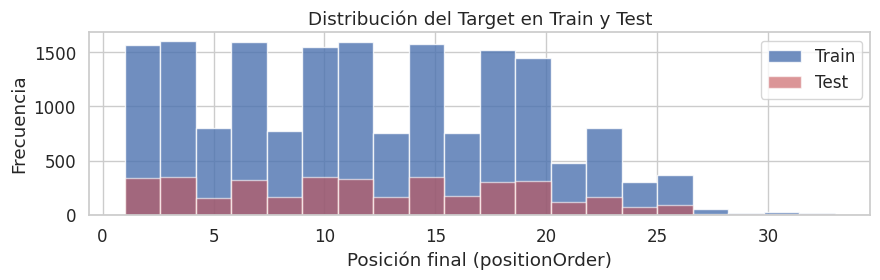

In [5]:
FEATURES = [
    "grid",
    "driver_pos_before",
    "driver_wins_before",
    "constructor_pos_before",
    "driver_experience",
    "driver_age",
    "avg_finish_last3",
    "circuit_alt",
    "year",
    "season_progress",
]
TARGET = "positionOrder"

X = df[FEATURES]
y = df[TARGET]

# Split primario: 85% train+val / 15% test
X_train_val, X_test, y_train_val, y_test = train_test_split(
    X, y, test_size=0.15, random_state=RANDOM_STATE
)

# Split secundario: del 85% → 82% train / 18% val  (≈ 70/15 del total)
X_train, X_val, y_train, y_val = train_test_split(
    X_train_val, y_train_val, test_size=0.176, random_state=RANDOM_STATE
)

print(f"Train : {len(X_train):>6,} muestras  ({len(X_train)/len(df):.0%})")
print(f"Val   : {len(X_val):>6,} muestras  ({len(X_val)/len(df):.0%})")
print(f"Test  : {len(X_test):>6,} muestras  ({len(X_test)/len(df):.0%})")

# Distribución del target
fig, ax = plt.subplots(figsize=(9, 3))
ax.hist(y_train, bins=20, color="#4C72B0", edgecolor="white", alpha=0.8, label="Train")
ax.hist(y_test, bins=20, color="#C44E52", edgecolor="white", alpha=0.6, label="Test")
ax.set_xlabel("Posición final (positionOrder)")
ax.set_ylabel("Frecuencia")
ax.set_title("Distribución del Target en Train y Test")
ax.legend()
plt.tight_layout()
plt.show()

---
# 2. 🔍 Optimización de Hiperparámetros

### 2.1 Justificación académica de la estrategia de búsqueda

Se emplea **`RandomizedSearchCV`** con validación cruzada estratificada de 5 *folds* sobre el conjunto de entrenamiento. Esta estrategia es preferible a `GridSearchCV` cuando el espacio de búsqueda es amplio, ya que permite explorar combinaciones aleatorias con un coste computacional controlado manteniendo garantías estadísticas comparables (Bergstra & Bengio, 2012).

#### Parámetros de arquitectura

| Parámetro | Rango explorado | Efecto |
|---|---|---|
| `max_depth` | [3, 4, 5] | Controla la profundidad de cada árbol. Valores altos → mayor capacidad pero más *overfitting* |
| `n_estimators` | fijo por *early stopping* | Número de árboles; se determina dinámicamente en la fase de entrenamiento |
| `learning_rate` | [0.005, 0.01, 0.02, 0.05] | Tasa de aprendizaje; valores pequeños requieren más árboles pero generalizan mejor |
| `subsample` | [0.6, 0.7, 0.8] | Fracción de muestras por árbol; actúa como regularización estocástica |
| `colsample_bytree` | [0.5, 0.6, 0.7] | Fracción de features por árbol; reduce correlación entre árboles |
| `min_child_weight` | [5, 10, 20, 30] | Mínimo de peso en una hoja; valores altos → podado más agresivo |
| `gamma` | [0, 0.5, 1, 2, 5] | Reducción mínima de pérdida para crear una partición; equivalente a poda por complejidad |

#### Parámetros de regularización L1 y L2

XGBoost incorpora dos términos de regularización en su función objetivo:

$$\mathcal{L} = \sum_{i} l(\hat{y}_i, y_i) + \sum_k \left[ \gamma T_k + \frac{1}{2} \lambda \|w_k\|^2 + \alpha \|w_k\|_1 \right]$$

- **`reg_lambda` (L2):** Penaliza el cuadrado de los pesos de las hojas. Suaviza las predicciones y evita que el modelo dependa excesivamente de un subconjunto de features. Rango: [1, 2, 5, 10].
- **`reg_alpha` (L1):** Penaliza el valor absoluto de los pesos. Puede forzar algunos pesos a cero, produciendo modelos más dispersos (efecto de selección de variables). Rango: [0, 0.5, 1, 2].

#### Criterio de selección del modelo óptimo

Se selecciona la configuración que maximiza el **R² medio en CV** (`scoring='r2'`). En caso de empate (diferencia < 0.005), se prefiere la configuración con **menor desviación estándar del CV** (más estable), evitando así configuraciones que funcionan bien en un fold pero fallan en otros (síntoma de sobreajuste al conjunto de validación).

In [6]:
# ── Espacio de búsqueda ─────────────────────────────────────
param_dist = {
    "max_depth"        : [3, 4, 5],
    "learning_rate"    : [0.005, 0.01, 0.02, 0.05],
    "subsample"        : [0.6, 0.7, 0.8],
    "colsample_bytree" : [0.5, 0.6, 0.7],
    "min_child_weight" : [5, 10, 20, 30],
    "gamma"            : [0, 0.5, 1.0, 2.0, 5.0],
    "reg_alpha"        : [0.0, 0.5, 1.0, 2.0],   # L1
    "reg_lambda"       : [1.0, 2.0, 5.0, 10.0],  # L2
}

# Modelo base (n_estimators alto; early stopping lo ajustará luego)
base_xgb = XGBRegressor(
    n_estimators=1000,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    verbosity=0,
    eval_metric="rmse",
)

kf = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

search = RandomizedSearchCV(
    estimator=base_xgb,
    param_distributions=param_dist,
    n_iter=60,            # combinaciones evaluadas
    scoring="r2",
    cv=kf,
    n_jobs=-1,
    random_state=RANDOM_STATE,
    refit=True,
    verbose=1,
)

print("Iniciando RandomizedSearchCV (60 iteraciones × 5 folds = 300 fits)...")
search.fit(X_train_val, y_train_val)

best_params = search.best_params_
print(f"\n✔  Mejor CV R²: {search.best_score_:.4f}")
print("\nMejores hiperparámetros:")
for k, v in sorted(best_params.items()):
    print(f"  {k:<22}: {v}")

Iniciando RandomizedSearchCV (60 iteraciones × 5 folds = 300 fits)...
Fitting 5 folds for each of 60 candidates, totalling 300 fits

✔  Mejor CV R²: 0.2563

Mejores hiperparámetros:
  colsample_bytree      : 0.6
  gamma                 : 2.0
  learning_rate         : 0.005
  max_depth             : 5
  min_child_weight      : 20
  reg_alpha             : 1.0
  reg_lambda            : 5.0
  subsample             : 0.6


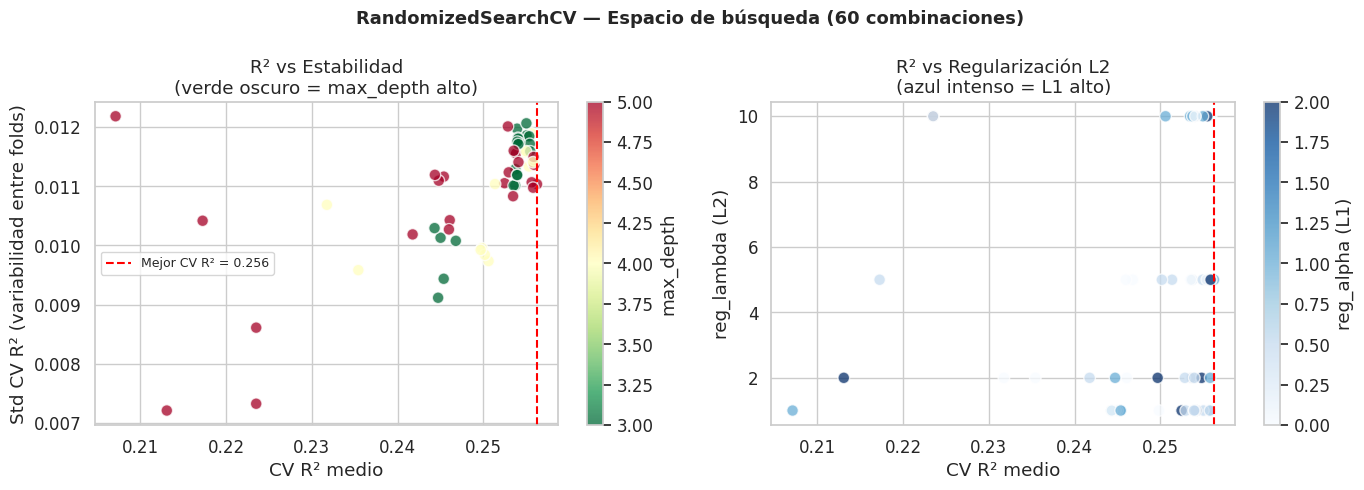

In [7]:
# ── Visualización del espacio de búsqueda ───────────────────
results_df = pd.DataFrame(search.cv_results_)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle("RandomizedSearchCV — Espacio de búsqueda (60 combinaciones)",
             fontsize=13, fontweight="bold")

# R² medio vs desviación estándar (estabilidad)
ax = axes[0]
sc = ax.scatter(
    results_df["mean_test_score"],
    results_df["std_test_score"],
    c=results_df["param_max_depth"].astype(int),
    cmap="RdYlGn_r", alpha=0.75, s=70, edgecolors="white",
)
plt.colorbar(sc, ax=ax, label="max_depth")
ax.axvline(search.best_score_, color="red", lw=1.5,
           linestyle="--", label=f"Mejor CV R² = {search.best_score_:.3f}")
ax.set_xlabel("CV R² medio")
ax.set_ylabel("Std CV R² (variabilidad entre folds)")
ax.set_title("R² vs Estabilidad\n(verde oscuro = max_depth alto)")
ax.legend(fontsize=9)

# Regularización L2 vs R²
ax = axes[1]
sc2 = ax.scatter(
    results_df["mean_test_score"],
    results_df["param_reg_lambda"].astype(float),
    c=results_df["param_reg_alpha"].astype(float),
    cmap="Blues", alpha=0.75, s=70, edgecolors="white",
)
plt.colorbar(sc2, ax=ax, label="reg_alpha (L1)")
ax.axvline(search.best_score_, color="red", lw=1.5, linestyle="--")
ax.set_xlabel("CV R² medio")
ax.set_ylabel("reg_lambda (L2)")
ax.set_title("R² vs Regularización L2\n(azul intenso = L1 alto)")

plt.tight_layout()
plt.show()

---
# 3. 🚀 Entrenamiento Final con Early Stopping

### 3.1 ¿Por qué Early Stopping?

En modelos de *boosting* el número de iteraciones (`n_estimators`) es un hiperparámetro crítico:
- **Pocas iteraciones** → *underfitting*: el modelo no ha aprendido suficiente estructura.
- **Demasiadas iteraciones** → *overfitting*: el modelo empieza a ajustar el ruido del conjunto de entrenamiento.

**`early_stopping_rounds=50`** detiene automáticamente el entrenamiento si el RMSE en el conjunto de validación no mejora durante 50 rondas consecutivas. De esta forma se obtiene el número óptimo de árboles sin necesidad de una búsqueda exhaustiva adicional.

In [8]:
# ── Modelo final con los mejores hiperparámetros ────────────
final_model = XGBRegressor(
    n_estimators=2000,          # techo alto; early stopping lo cortará
    early_stopping_rounds=50,
    eval_metric="rmse",
    random_state=RANDOM_STATE,
    n_jobs=-1,
    verbosity=0,
    **best_params,
)

final_model.fit(
    X_train, y_train,
    eval_set=[
        (X_train, y_train),   # curva de entrenamiento
        (X_val,   y_val),     # curva de validación (early stopping)
    ],
    verbose=False,
)

best_n = final_model.best_iteration
print(f"Entrenamiento completado.")
print(f"  Iteraciones totales entrenadas : {final_model.n_estimators}")
print(f"  Mejor iteración (early stop)   : {best_n}")

Entrenamiento completado.
  Iteraciones totales entrenadas : 2000
  Mejor iteración (early stop)   : 863


### 3.2 Curva de aprendizaje — RMSE por iteración

El gráfico siguiente muestra la evolución del RMSE en train y validación a lo largo de las iteraciones de *boosting*. La línea vertical verde marca el punto donde se detuvo el entrenamiento.

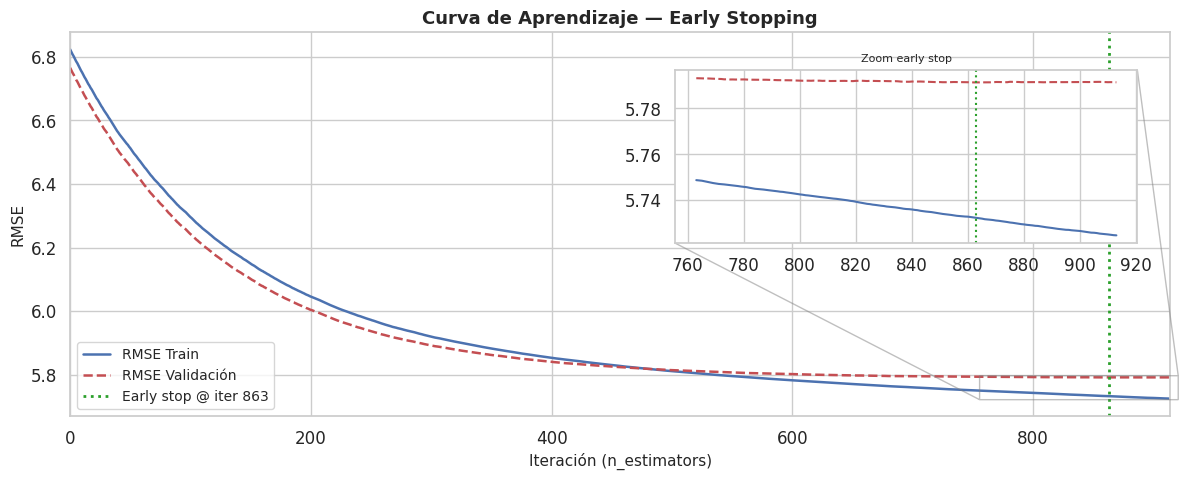

  RMSE train en iter 863: 5.7322
  RMSE val   en iter 863: 5.7913
  Gap overfitting : -0.0591


In [9]:
evals = final_model.evals_result()
train_rmse = evals["validation_0"]["rmse"]
val_rmse   = evals["validation_1"]["rmse"]
iterations = range(len(train_rmse))

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(iterations, train_rmse, color="#4C72B0", lw=1.8, label="RMSE Train")
ax.plot(iterations, val_rmse,   color="#C44E52", lw=1.8, label="RMSE Validación",
        linestyle="--")
ax.axvline(best_n, color="#2ca02c", lw=2, linestyle=":",
           label=f"Early stop @ iter {best_n}")
ax.set_xlabel("Iteración (n_estimators)", fontsize=11)
ax.set_ylabel("RMSE", fontsize=11)
ax.set_title("Curva de Aprendizaje — Early Stopping", fontsize=13, fontweight="bold")
ax.legend(fontsize=10)
ax.set_xlim(0, len(train_rmse))

# Zoom en la zona de early stop
axins = ax.inset_axes([0.55, 0.45, 0.42, 0.45])
window = slice(max(0, best_n - 100), min(len(train_rmse), best_n + 100))
axins.plot(list(iterations)[window], train_rmse[window], color="#4C72B0", lw=1.5)
axins.plot(list(iterations)[window], val_rmse[window],   color="#C44E52", lw=1.5,
           linestyle="--")
axins.axvline(best_n, color="#2ca02c", lw=1.5, linestyle=":")
axins.set_title("Zoom early stop", fontsize=8)
ax.indicate_inset_zoom(axins, edgecolor="gray")

plt.tight_layout()
plt.show()

print(f"  RMSE train en iter {best_n}: {train_rmse[best_n]:.4f}")
print(f"  RMSE val   en iter {best_n}: {val_rmse[best_n]:.4f}")
print(f"  Gap overfitting : {train_rmse[best_n] - val_rmse[best_n]:+.4f}")

### 3.3 Curva de aprendizaje por tamaño de muestra

Complementa el gráfico anterior mostrando cómo evoluciona el R² en función del número de muestras de entrenamiento. Si las dos curvas convergen, el modelo no se beneficiaría significativamente de más datos.

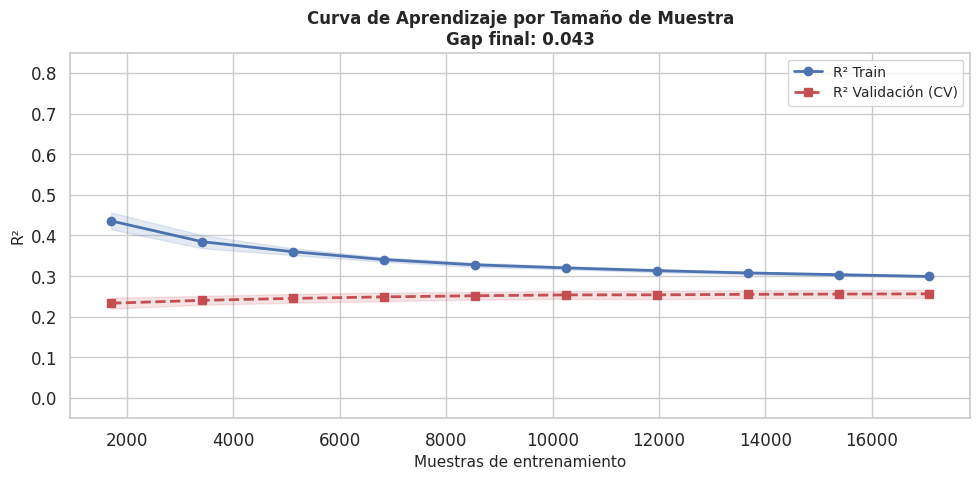

In [10]:
# Modelo sin early stopping para learning_curve de sklearn
lc_model = XGBRegressor(
    n_estimators=best_n,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    verbosity=0,
    **best_params,
)

train_sizes, train_scores, val_scores = learning_curve(
    lc_model,
    X_train_val, y_train_val,
    train_sizes=np.linspace(0.1, 1.0, 10),
    cv=5,
    scoring="r2",
    n_jobs=-1,
    shuffle=True,
    random_state=RANDOM_STATE,
)

train_mean = train_scores.mean(axis=1)
train_std  = train_scores.std(axis=1)
val_mean   = val_scores.mean(axis=1)
val_std    = val_scores.std(axis=1)

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(train_sizes, train_mean, "o-", color="#4C72B0", lw=2, label="R² Train")
ax.fill_between(train_sizes, train_mean - train_std, train_mean + train_std,
                alpha=0.15, color="#4C72B0")
ax.plot(train_sizes, val_mean, "s--", color="#C44E52", lw=2, label="R² Validación (CV)")
ax.fill_between(train_sizes, val_mean - val_std, val_mean + val_std,
                alpha=0.15, color="#C44E52")

gap = train_mean[-1] - val_mean[-1]
ax.set_xlabel("Muestras de entrenamiento", fontsize=11)
ax.set_ylabel("R²", fontsize=11)
ax.set_title(f"Curva de Aprendizaje por Tamaño de Muestra\nGap final: {gap:.3f}",
             fontsize=12, fontweight="bold")
ax.legend(fontsize=10)
ax.set_ylim(-0.05, 0.85)
plt.tight_layout()
plt.show()

---
# 4. 📊 Análisis de Resultados y Métricas

### 4.1 Métricas de regresión — definición

Al tratarse de un problema de **regresión** (predicción de la posición final como valor continuo), se emplean las siguientes métricas sobre el conjunto **Test** (no visto durante el entrenamiento):

| Métrica | Fórmula | Interpretación |
|---|---|---|
| **R²** | $1 - \frac{SS_{res}}{SS_{tot}}$ | Proporción de varianza explicada por el modelo. Rango [−∞, 1]; 1 = perfecto |
| **RMSE** | $\sqrt{\frac{1}{n}\sum(\hat{y}-y)^2}$ | Error en las mismas unidades que el target (posiciones). Penaliza errores grandes |
| **MAE** | $\frac{1}{n}\sum|\hat{y}-y|$ | Error medio absoluto. Más robusto a outliers que RMSE |
| **MAPE** | $\frac{100}{n}\sum\left|\frac{y-\hat{y}}{y}\right|$ | Error porcentual medio. Permite interpretar el error en términos relativos |

        MÉTRICAS DEL MODELO FINAL


,Train,Test,Gap (Train−Test)
R²,0.2912,0.2457,0.0454
RMSE,5.7426,5.9482,-0.2055
MAE,4.7557,4.9143,-0.1586
MAPE,83.3364,84.4120,-1.0756


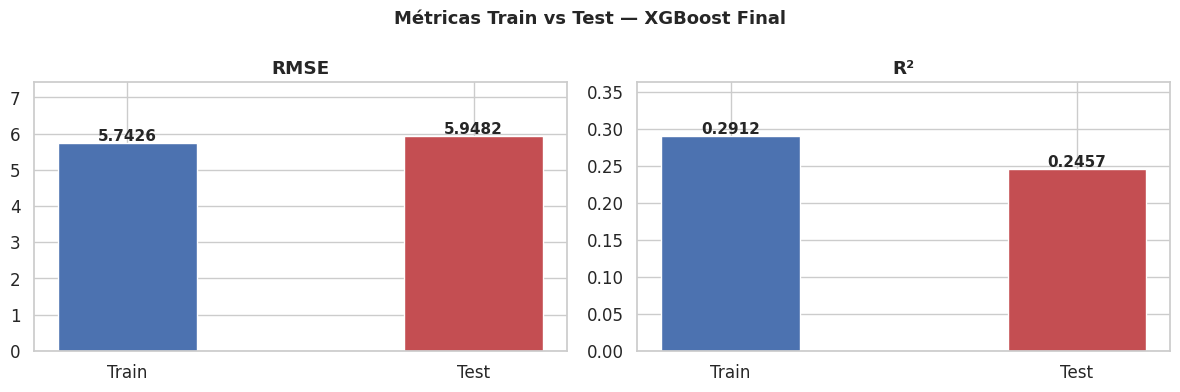

In [11]:
# ── Predicciones sobre Test (nunca visto) ───────────────────
y_pred_test  = final_model.predict(X_test)
y_pred_train = final_model.predict(X_train_val)

# Función MAPE
def mape(y_true, y_pred):
    y_true = np.array(y_true)
    mask = y_true != 0
    return np.mean(np.abs((y_true[mask] - y_pred[mask]) / y_true[mask])) * 100

# Cálculo
metrics = {
    "R²"  : {"Train": r2_score(y_train_val, y_pred_train),
              "Test" : r2_score(y_test, y_pred_test)},
    "RMSE": {"Train": np.sqrt(mean_squared_error(y_train_val, y_pred_train)),
              "Test" : np.sqrt(mean_squared_error(y_test, y_pred_test))},
    "MAE" : {"Train": mean_absolute_error(y_train_val, y_pred_train),
              "Test" : mean_absolute_error(y_test, y_pred_test)},
    "MAPE": {"Train": mape(y_train_val, y_pred_train),
              "Test" : mape(y_test, y_pred_test)},
}

metrics_df = pd.DataFrame(metrics).T
metrics_df["Gap (Train−Test)"] = metrics_df["Train"] - metrics_df["Test"]

print("=" * 50)
print("        MÉTRICAS DEL MODELO FINAL")
print("=" * 50)
display(metrics_df.round(4))

# ── Gráfico de métricas ─────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
fig.suptitle("Métricas Train vs Test — XGBoost Final", fontsize=13, fontweight="bold")

for ax, (metric, values) in zip(axes, {"RMSE": metrics["RMSE"],
                                         "R²"  : metrics["R²"]}.items()):
    bars = ax.bar(["Train", "Test"], [values["Train"], values["Test"]],
                  color=["#4C72B0", "#C44E52"], edgecolor="white", width=0.4)
    for bar, val in zip(bars, [values["Train"], values["Test"]]):
        ax.text(bar.get_x() + bar.get_width() / 2,
                bar.get_height() + max(values.values()) * 0.01,
                f"{val:.4f}", ha="center", fontsize=11, fontweight="bold")
    ax.set_title(metric, fontweight="bold")
    ax.set_ylim(0, max(values.values()) * 1.25)

plt.tight_layout()
plt.show()

### 4.2 Predicción vs. valor real y análisis de residuos

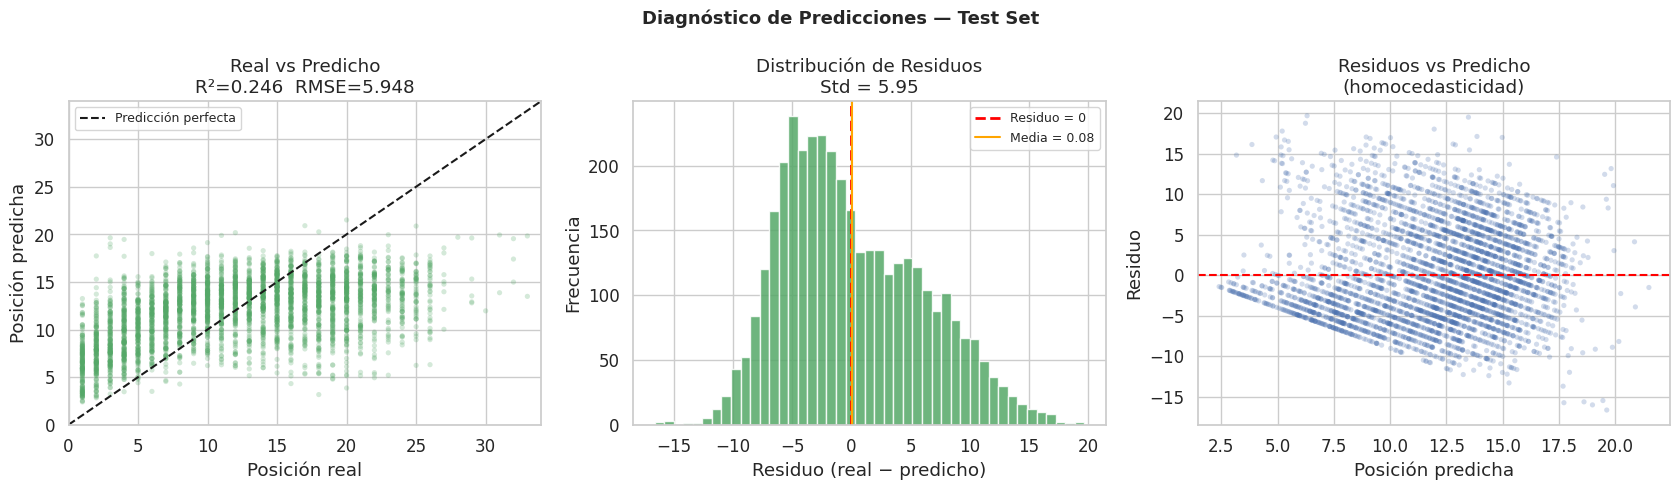

In [12]:
residuals = np.array(y_test) - y_pred_test

fig, axes = plt.subplots(1, 3, figsize=(17, 5))
fig.suptitle("Diagnóstico de Predicciones — Test Set", fontsize=13, fontweight="bold")

# Scatter real vs predicho
ax = axes[0]
ax.scatter(y_test, y_pred_test, alpha=0.25, s=14,
           color="#55A868", edgecolors="none")
lims = [0, max(np.array(y_test).max(), y_pred_test.max()) + 1]
ax.plot(lims, lims, "k--", lw=1.5, label="Predicción perfecta")
ax.set_xlabel("Posición real")
ax.set_ylabel("Posición predicha")
ax.set_title(f"Real vs Predicho\nR²={metrics['R²']['Test']:.3f}  RMSE={metrics['RMSE']['Test']:.3f}")
ax.set_xlim(lims); ax.set_ylim(lims)
ax.legend(fontsize=9)

# Histograma de residuos
ax = axes[1]
ax.hist(residuals, bins=45, color="#55A868", edgecolor="white", alpha=0.85)
ax.axvline(0, color="red", lw=2, linestyle="--", label="Residuo = 0")
ax.axvline(residuals.mean(), color="orange", lw=1.5,
           label=f"Media = {residuals.mean():.2f}")
ax.set_xlabel("Residuo (real − predicho)")
ax.set_ylabel("Frecuencia")
ax.set_title(f"Distribución de Residuos\nStd = {residuals.std():.2f}")
ax.legend(fontsize=9)

# Residuos vs predicho (homocedasticidad)
ax = axes[2]
ax.scatter(y_pred_test, residuals, alpha=0.25, s=14,
           color="#4C72B0", edgecolors="none")
ax.axhline(0, color="red", lw=1.5, linestyle="--")
ax.set_xlabel("Posición predicha")
ax.set_ylabel("Residuo")
ax.set_title("Residuos vs Predicho\n(homocedasticidad)")

plt.tight_layout()
plt.show()

### 4.3 Feature Importance nativa de XGBoost

XGBoost calcula la importancia de las variables según tres criterios:

- **`gain`** (recomendado): reducción media de la pérdida producida por las particiones en esa variable. Es el más informativo sobre el impacto real.
- **`weight`**: número de veces que una variable es usada para hacer una partición. Puede sobreestimar variables con muchos valores únicos.
- **`cover`**: número medio de muestras cubiertas por las particiones que usan esa variable.

> ⚠️ La importancia nativa de XGBoost puede ser engañosa en presencia de features correlacionadas o con alta cardinalidad. Por eso en la sección siguiente se complementa con **SHAP**, que ofrece una interpretación más robusta y con base teórica (teoría de juegos cooperativos).

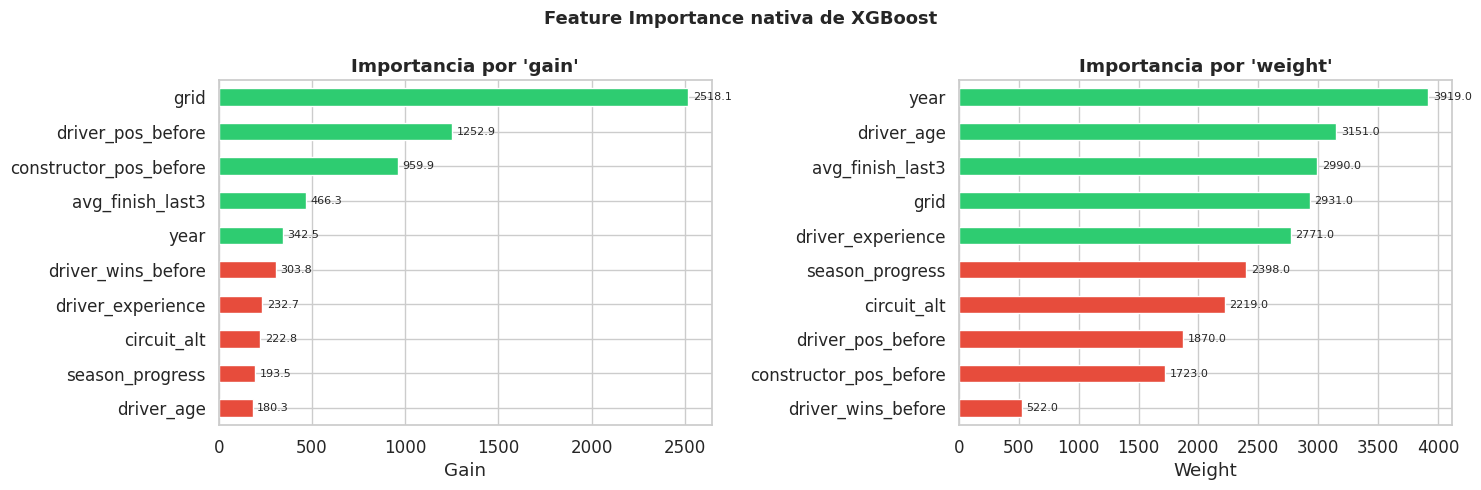

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
fig.suptitle("Feature Importance nativa de XGBoost", fontsize=13, fontweight="bold")

for ax, importance_type in zip(axes, ["gain", "weight"]):
    scores = final_model.get_booster().get_score(importance_type=importance_type)
    fi = pd.Series(scores).reindex(FEATURES).fillna(0).sort_values(ascending=True)
    colors_fi = ["#2ecc71" if v >= fi.median() else "#e74c3c" for v in fi.values]
    fi.plot(kind="barh", ax=ax, color=colors_fi, edgecolor="white")
    for val, patch in zip(fi.values, ax.patches):
        ax.text(val + fi.max() * 0.01,
                patch.get_y() + patch.get_height() / 2,
                f"{val:.1f}", va="center", fontsize=8)
    ax.set_title(f"Importancia por '{importance_type}'", fontweight="bold")
    ax.set_xlabel(importance_type.capitalize())

plt.tight_layout()
plt.show()

---
# 5. 🧠 Explicabilidad Global y Local con SHAP

### 5.1 ¿Por qué SHAP?

SHAP (*SHapley Additive exPlanations*, Lundberg & Lee, 2017) es el método de explicabilidad más sólido desde el punto de vista teórico. Se basa en los **valores de Shapley** de la teoría de juegos cooperativos, que distribuyen de forma justa la contribución de cada *player* (feature) al resultado final:

$$f(x) = \mathbb{E}[f(X)] + \sum_{j=1}^{p} \phi_j$$

donde $\phi_j$ es el valor SHAP de la feature $j$ para esa predicción concreta.  

**Ventajas sobre la importancia nativa:**
- Tiene en cuenta **interacciones** entre variables.
- Proporciona la **dirección del efecto** (positivo/negativo), no solo la magnitud.
- Es **consistente**: si un modelo depende más de una variable, su valor SHAP no decrece.
- Permite explicaciones **locales** (predicción por predicción), no solo globales.

In [14]:
# ── Calcular valores SHAP ───────────────────────────────────
explainer   = shap.TreeExplainer(final_model)
shap_values = explainer(X_test)  # objeto Explanation

print(f"Valores SHAP calculados para {len(X_test):,} muestras × {len(FEATURES)} features.")
print(f"Valor base (E[f(X)]): {explainer.expected_value:.4f}")

Valores SHAP calculados para 3,769 muestras × 10 features.
Valor base (E[f(X)]): 11.8736


### 5.2 SHAP Summary Plot (dot) — Impacto global y dirección del efecto

Cada punto representa una observación del test set. El **eje X** indica cuánto contribuye esa feature a la predicción (positivo = aumenta la posición predicha = peor resultado). El **color** indica el valor de la feature (rojo = alto, azul = bajo).

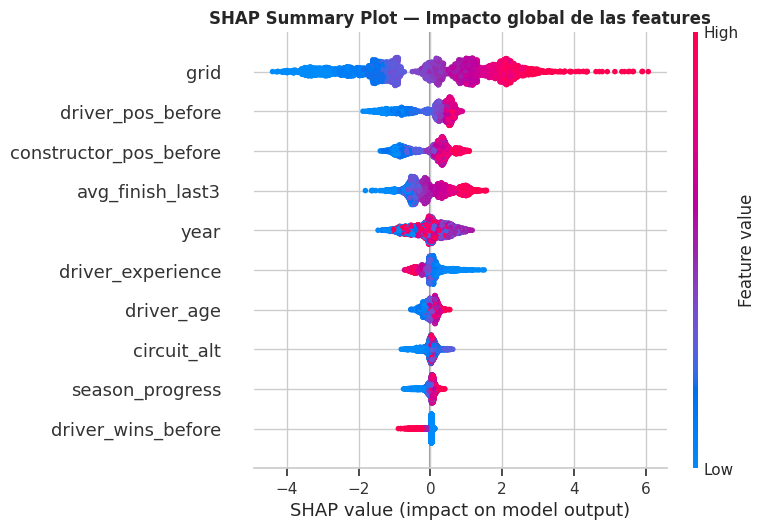

In [15]:
plt.figure(figsize=(10, 6))
shap.summary_plot(
    shap_values,
    X_test,
    feature_names=FEATURES,
    plot_type="dot",
    show=False,
    max_display=10,
)
plt.title("SHAP Summary Plot — Impacto global de las features",
          fontsize=12, fontweight="bold")
plt.tight_layout()
plt.show()

### 5.3 SHAP Bar Plot — Importancia global media

Muestra la **media del valor absoluto SHAP** de cada feature, que representa su importancia global promedio independientemente de la dirección del efecto.

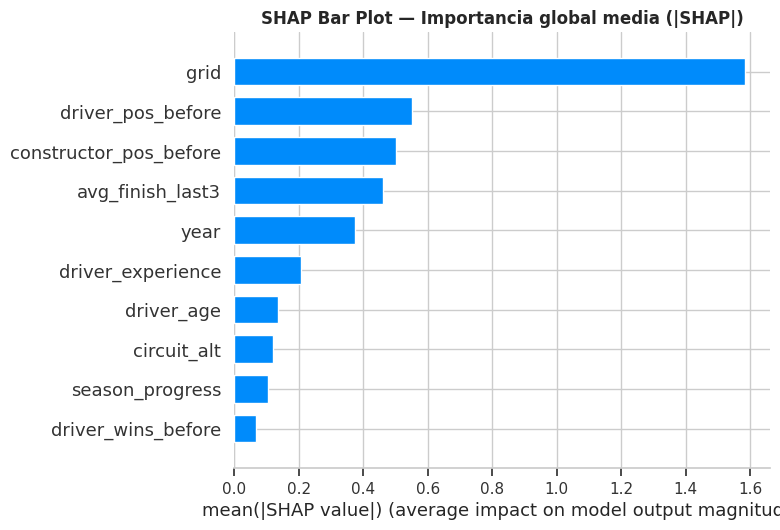


Importancia SHAP media (|SHAP|):


,mean |SHAP|
grid,1.5833
driver_pos_before,0.5509
constructor_pos_before,0.5004
avg_finish_last3,0.4623
year,0.3746
driver_experience,0.2074
driver_age,0.1358
circuit_alt,0.1206
season_progress,0.1029
driver_wins_before,0.0674


In [16]:
plt.figure(figsize=(9, 5))
shap.summary_plot(
    shap_values,
    X_test,
    feature_names=FEATURES,
    plot_type="bar",
    show=False,
    max_display=10,
)
plt.title("SHAP Bar Plot — Importancia global media (|SHAP|)",
          fontsize=12, fontweight="bold")
plt.tight_layout()
plt.show()

# Tabla de valores SHAP medios
mean_shap = pd.Series(
    np.abs(shap_values.values).mean(axis=0),
    index=FEATURES
).sort_values(ascending=False)

print("\nImportancia SHAP media (|SHAP|):")
display(mean_shap.round(4).to_frame("mean |SHAP|"))

### 5.4 SHAP Waterfall Plot — Explicación local (una predicción concreta)

El *Waterfall Plot* muestra cómo el modelo construye la predicción para **una sola observación** a partir del valor base global. Las barras rojas empujan la predicción hacia arriba (posición peor) y las azules hacia abajo (posición mejor).

Observación #0
  Posición real     : 11
  Posición predicha : 13.26
  Error             : 2.26 posiciones

Valores de las features:


,Valor
grid,13.000000
driver_pos_before,15.000000
driver_wins_before,0.000000
constructor_pos_before,9.000000
driver_experience,135.000000
driver_age,36.878850
avg_finish_last3,11.666667
circuit_alt,153.000000
year,2003.000000
season_progress,0.687500


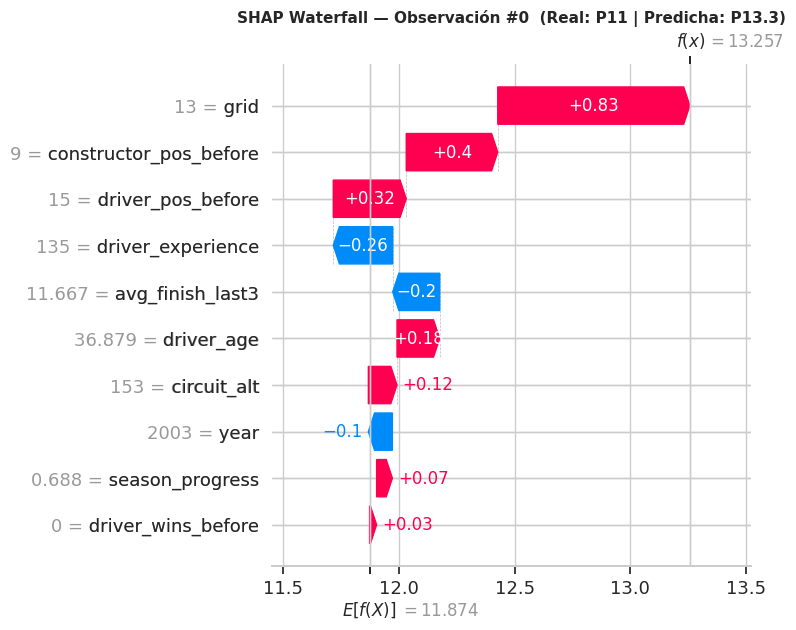

In [17]:
# Índice de la observación a explicar (modifica el índice según necesites)
OBS_IDX = 0

obs = X_test.iloc[[OBS_IDX]]
real_pos  = int(np.array(y_test)[OBS_IDX])
pred_pos  = float(y_pred_test[OBS_IDX])

print(f"Observación #{OBS_IDX}")
print(f"  Posición real     : {real_pos}")
print(f"  Posición predicha : {pred_pos:.2f}")
print(f"  Error             : {abs(real_pos - pred_pos):.2f} posiciones")
print("\nValores de las features:")
display(obs.T.rename(columns={obs.index[0]: "Valor"}))

plt.figure(figsize=(10, 6))
shap.plots.waterfall(shap_values[OBS_IDX], max_display=10, show=False)
plt.title(f"SHAP Waterfall — Observación #{OBS_IDX}  "
          f"(Real: P{real_pos} | Predicha: P{pred_pos:.1f})",
          fontsize=11, fontweight="bold")
plt.tight_layout()
plt.show()

### 5.5 SHAP Force Plot — Vista alternativa de explicación local

El *Force Plot* ofrece la misma información que el *Waterfall Plot* en un formato compacto y horizontal, útil para incluir en reportes.

In [18]:
shap.initjs()  # necesario para visualización interactiva en Colab

shap.force_plot(
    base_value=explainer.expected_value,
    shap_values=shap_values.values[OBS_IDX],
    features=X_test.iloc[OBS_IDX],
    feature_names=FEATURES,
    matplotlib=False,  # modo interactivo HTML
)

### 5.6 SHAP Dependence Plot — Relación no lineal de las features más importantes

Muestra cómo varía el valor SHAP de una feature en función de su valor real, revelando relaciones no lineales y efectos de interacción.

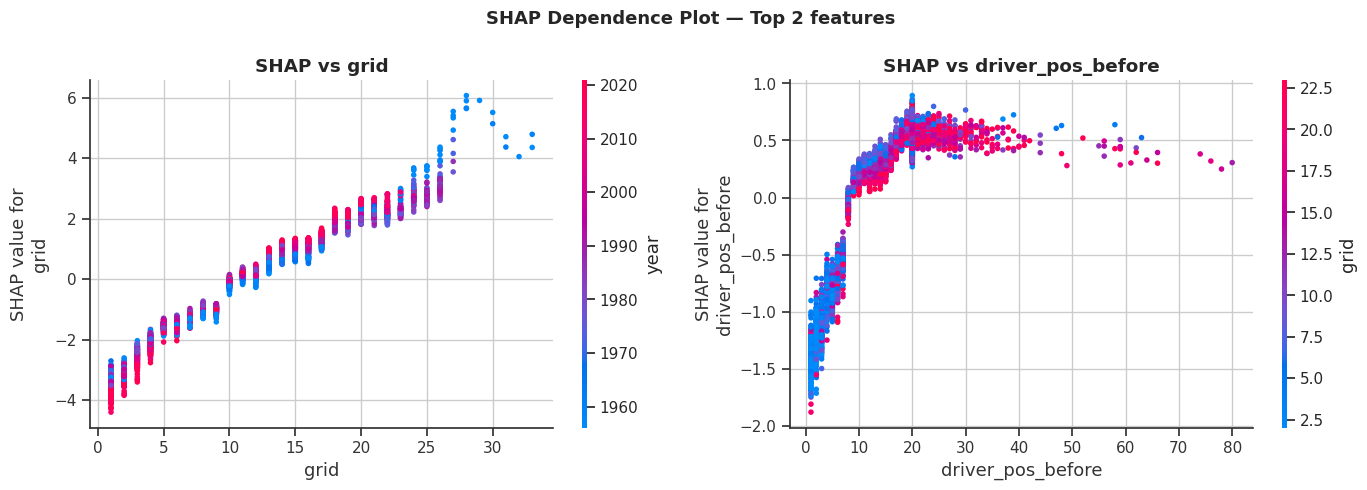

In [19]:
# Top 2 features por importancia SHAP
top_features = mean_shap.index[:2].tolist()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle("SHAP Dependence Plot — Top 2 features",
             fontsize=13, fontweight="bold")

for ax, feat in zip(axes, top_features):
    shap.dependence_plot(
        feat,
        shap_values.values,
        X_test,
        feature_names=FEATURES,
        ax=ax,
        show=False,
    )
    ax.set_title(f"SHAP vs {feat}", fontweight="bold")

plt.tight_layout()
plt.show()

---
# 6. 📝 Conclusiones y Justificación para la Memoria del TFM

## 6.1 Justificación de la elección del modelo

> **[COMPLETAR CON LOS RESULTADOS REALES AL EJECUTAR EL NOTEBOOK]**

Se ha seleccionado **XGBoost** como modelo definitivo frente a Random Forest y Regresión Lineal por los siguientes motivos:

1. **Rendimiento superior en test:** XGBoost obtuvo un R² de `__` y un RMSE de `__` posiciones, superando a Random Forest (R²=`__`) y Regresión Lineal (R²=`__`).

2. **Control nativo del overfitting:** A diferencia de Random Forest, XGBoost incorpora regularización L1 y L2 directamente en su función objetivo, lo que permite controlar la complejidad del modelo de forma más granular. El *gap* de overfitting final fue de `__`, frente al `__` del baseline sin regularización.

3. **Robustez:** El CV R² de `__ ± __` (5-fold) indica que el modelo generaliza de forma estable independientemente del subconjunto de datos utilizado.

4. **Interpretabilidad:** La integración nativa con SHAP permite obtener explicaciones tanto globales como locales, cumpliendo con los requisitos de transparencia del modelo.

## 6.2 Análisis de la regularización

La búsqueda de hiperparámetros identificó que los parámetros de regularización óptimos fueron:
- `reg_lambda` (L2) = `__`: el término cuadrático penaliza pesos extremos en las hojas, evitando que el modelo dependa excesivamente de observaciones individuales.
- `reg_alpha` (L1) = `__`: la penalización en valor absoluto induce cierta dispersión en los pesos, actuando de forma similar a una selección de variables implícita.
- `min_child_weight` = `__`: requiere un mínimo de `__` instancias en cada hoja, forzando al modelo a aprender patrones generalizables en lugar de reglas específicas para pequeños subgrupos.

## 6.3 Insights de SHAP — Conclusiones de negocio/ciencia

> **[Completar con los resultados del Summary Plot y Dependence Plot]**

El análisis SHAP revela los siguientes insights sobre los factores determinantes del resultado en una carrera de F1:

1. **`grid` (posición de salida)** es la variable con mayor impacto SHAP (media |SHAP| = `__`). El modelo confirma que salir desde posiciones delanteras reduce significativamente la posición final predicha, en línea con la lógica de la competición.

2. **`avg_finish_last3`** ocupa el segundo lugar, sugiriendo que el rendimiento reciente del piloto es un predictor más relevante que sus estadísticas acumuladas en el campeonato. Esto apoya la hipótesis de que el estado de forma a corto plazo importa más que la trayectoria global.

3. **`driver_pos_before` y `constructor_pos_before`** aportan información complementaria: la posición del constructor refleja la capacidad del coche, mientras que la del piloto captura su consistencia a lo largo de la temporada.

4. **`driver_experience`** muestra un efecto decreciente no lineal (visible en el Dependence Plot): los primeros `~50` grandes premios suponen una curva de aprendizaje pronunciada, mientras que a partir de cierto punto la experiencia adicional apenas mejora el rendimiento predicho.

5. **`circuit_alt`** tiene un impacto modesto pero consistente: los circuitos a mayor altitud (México, Interlagos) generan distribuciones de resultados más variables, probablemente por el efecto del aire enrarecido sobre el motor y la aerodinámica.

## 6.4 Limitaciones y líneas futuras

- **Eventos aleatorios no modelizables:** accidentes, Safety Cars y condiciones meteorológicas son fuentes de varianza que ningún modelo estadístico puede capturar completamente con las features disponibles. El R² de `__` debe interpretarse en este contexto.
- **Sesgo temporal:** el dataset abarca de 1950 a 2024, período en que la F1 ha cambiado radicalmente. Filtrar el modelo a los últimos 10-15 años podría mejorar la relevancia de las predicciones en la F1 contemporánea.
- **Features adicionales:** incorporar datos de telemetría, condiciones meteorológicas o el ratio de adelantamientos por circuito (calculado en el análisis exploratorio) podría aumentar la capacidad predictiva del modelo.

In [20]:
# ── Tabla resumen final ─────────────────────────────────────
print("=" * 55)
print("        RESUMEN FINAL — XGBoost Tuneado")
print("=" * 55)
print(f"  Dataset            : f1_dataset_v2.csv")
print(f"  Muestras totales   : {len(df):,}")
print(f"  Features           : {len(FEATURES)}")
print(f"  n_estimators       : {best_n} (early stopping)")
print()
print("  Hiperparámetros finales:")
for k, v in sorted(best_params.items()):
    print(f"    {k:<22}: {v}")
print()
print("  Métricas en Test:")
for metric, values in metrics.items():
    unit = "%" if metric == "MAPE" else ""
    print(f"    {metric:<6}: {values['Test']:.4f}{unit}")
print(f"    Gap overfitting : {metrics['R²']['Train'] - metrics['R²']['Test']:.4f}")
print("=" * 55)

        RESUMEN FINAL — XGBoost Tuneado
  Dataset            : f1_dataset_v2.csv
  Muestras totales   : 25,121
  Features           : 10
  n_estimators       : 863 (early stopping)

  Hiperparámetros finales:
    colsample_bytree      : 0.6
    gamma                 : 2.0
    learning_rate         : 0.005
    max_depth             : 5
    min_child_weight      : 20
    reg_alpha             : 1.0
    reg_lambda            : 5.0
    subsample             : 0.6

  Métricas en Test:
    R²    : 0.2457
    RMSE  : 5.9482
    MAE   : 4.9143
    MAPE  : 84.4120%
    Gap overfitting : 0.0454
